In [1]:
!pip install effdet timm albumentations pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.5/112.5 kB 4.1 MB/s eta 0:00:00


In [2]:
import os
import glob
import cv2
import shutil
import random
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import albumentations as A
from albumentations.pytorch.transforms import ToTensorV2
from effdet import get_efficientdet_config, EfficientDet, DetBenchPredict
from effdet.efficientdet import HeadNet

# Select hardware device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# 1. Locate the TFP-BD dataset
INPUT_DATASET_PATH = None
for root, dirs, files in os.walk("/kaggle/input"):
    if 'tfp_dataset' in dirs:
        INPUT_DATASET_PATH = os.path.join(root, 'tfp_dataset')
        break

if not INPUT_DATASET_PATH:
    raise FileNotFoundError("Could not locate 'tfp_dataset'. Ensure the dataset is mounted in your notebook.")
print(f"Dataset located at: {INPUT_DATASET_PATH}")

# 2. Locate the unzipped weight folder containing data.pkl
WEIGHTS_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "data.pkl" in files:
        WEIGHTS_DIR = root
        break

if not WEIGHTS_DIR:
    raise FileNotFoundError("Could not find the extracted weights directory containing 'data.pkl'.")
print(f"Extracted weight directory located at: {WEIGHTS_DIR}")

Device: cuda
Dataset located at: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset
Extracted weight directory located at: /kaggle/input/datasets/sharminaktermukta/efficientnetd3-30-epoch/effdet_d3_epoch_30


In [3]:
import os
import zipfile
import torch
from effdet import get_efficientdet_config, EfficientDet, DetBenchPredict
from effdet.efficientdet import HeadNet

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. Search for an intact .pth file first, or locate the unzipped data.pkl folder
weights_path = None
unzipped_weights_dir = None

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f == "effdet_d3_epoch_30.pth" or f.endswith(".pth"):
            weights_path = os.path.join(root, f)
            break
    if "data.pkl" in files and "version" in files:
        unzipped_weights_dir = root
    if weights_path:
        break

# 2. If only the unzipped dataset folder is mounted, rebuild a valid PyTorch archive
if not weights_path:
    if not unzipped_weights_dir:
        raise FileNotFoundError("Could not find either a .pth file or the unzipped weight files in /kaggle/input.")
    
    print(f"Found unzipped PyTorch weights at: {unzipped_weights_dir}")
    weights_path = "/kaggle/working/effdet_d3_epoch_30_fixed.pth"
    
    # PyTorch requires all files to be inside a single top-level folder ('archive/') with ZIP_STORED
    with zipfile.ZipFile(weights_path, 'w', compression=zipfile.ZIP_STORED) as zf:
        for root, dirs, files in os.walk(unzipped_weights_dir):
            for file in files:
                full_path = os.path.join(root, file)
                rel_path = os.path.relpath(full_path, unzipped_weights_dir)
                arcname = os.path.join("archive", rel_path)
                zf.write(full_path, arcname)
                
    print(f"Successfully rebuilt PyTorch checkpoint at: {weights_path}")
else:
    print(f"Found intact .pth file at: {weights_path}")

# 3. Configure EfficientDet-D3 architecture
CLASSES = ["Car", "Bus", "Truck", "Motorcycle", "Bicycle", "Rickshaw", "Mini-Truck", "CNG", "Pedestrian"]
NUM_CLASSES = len(CLASSES)
IMG_SIZE = 640

config = get_efficientdet_config('tf_efficientdet_d3')
config.image_size = (IMG_SIZE, IMG_SIZE)
config.num_classes = NUM_CLASSES

net = EfficientDet(config, pretrained_backbone=False)
net.class_net = HeadNet(config, num_outputs=NUM_CLASSES)

# 4. Load the weights and initialize inference benchmark
state_dict = torch.load(weights_path, map_location=device, weights_only=False)
net.load_state_dict(state_dict)

bench = DetBenchPredict(net)
bench.to(device)
bench.eval()
print("EfficientDet-D3 model loaded and ready for PCU inference!")

Found unzipped PyTorch weights at: /kaggle/input/datasets/sharminaktermukta/efficientnetd3-30-epoch/effdet_d3_epoch_30
Successfully rebuilt PyTorch checkpoint at: /kaggle/working/effdet_d3_epoch_30_fixed.pth
EfficientDet-D3 model loaded and ready for PCU inference!


In [4]:
# Class mapping matching dataset index (1-based from effdet)
class_mapping = {
    1: 'Car', 2: 'Bus', 3: 'Truck', 4: 'Motorcycle', 5: 'Bicycle',
    6: 'Rickshaw', 7: 'Mini-Truck', 8: 'CNG', 9: 'Pedestrian'
}

# Standard PCU conversion weights
pcu_weights = {
    'Car': 1.0,
    'Bus': 3.0,
    'Truck': 3.0,
    'Mini-Truck': 1.5,
    'CNG': 0.75,
    'Motorcycle': 0.75,
    'Rickshaw': 1.0,
    'Bicycle': 0.5,
    'Pedestrian': 0.0
}

def analyze_road_pcu(image_path, model, device, conf_threshold=0.30):
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape

    # Preprocess image
    transform = A.Compose([
        A.Resize(height=IMG_SIZE, width=IMG_SIZE),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])
    tensor_img = transform(image=img_rgb)['image'].unsqueeze(0).to(device)

    # Prepare scale and size tensors for effdet
    img_scales = torch.tensor([1.0], dtype=torch.float32).to(device)
    img_sizes = torch.tensor([[IMG_SIZE, IMG_SIZE]], dtype=torch.float32).to(device)
    img_info = {'img_scale': img_scales, 'img_size': img_sizes}

    with torch.no_grad():
        outputs = model(tensor_img, img_info)[0]

    # Filter by confidence
    valid_mask = outputs[:, 4] > conf_threshold
    predictions = outputs[valid_mask].cpu().numpy()

    total_pcu = 0.0
    encroachment_detected = False

    # Define roadside margins (outer 20% on each side)
    left_margin = w * 0.20
    right_margin = w * 0.80

    fig, ax = plt.subplots(1, figsize=(14, 10))
    ax.imshow(img_rgb)

    for pred in predictions:
        xmin, ymin, xmax, ymax, score, cls_id = pred

        # Rescale bounding box coordinates to original resolution
        xmin = (xmin / IMG_SIZE) * w
        xmax = (xmax / IMG_SIZE) * w
        ymin = (ymin / IMG_SIZE) * h
        ymax = (ymax / IMG_SIZE) * h

        cls_name = class_mapping.get(int(cls_id), "Unknown")
        box_color = 'deepskyblue'

        # Sum motorized and non-motorized vehicle PCU
        if cls_name in pcu_weights and cls_name != 'Pedestrian':
            total_pcu += pcu_weights[cls_name]

        # Encroachment check: pedestrians or slow entities crossing roadside margins
        if cls_name in ['Pedestrian', 'Rickshaw', 'Bicycle']:
            x_center = (xmin + xmax) / 2
            if x_center < left_margin or x_center > right_margin:
                encroachment_detected = True
                box_color = 'crimson'

        # Draw bounding boxes
        rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                 linewidth=2, edgecolor=box_color, facecolor='none')
        ax.add_patch(rect)
        ax.text(xmin, max(0, ymin - 6), f"{cls_name} {score:.2f}",
                color='white', fontsize=9, backgroundcolor=box_color, weight='bold')

    # Apply your PCU cutoffs
    if total_pcu < 8.45:
        congestion_level = "Low"
        c_color = "#28a745" # Green
    elif total_pcu <= 15.8:
        congestion_level = "Medium"
        c_color = "#ffc107" # Yellow
    else:
        congestion_level = "High"
        c_color = "#dc3545" # Red

    # Determine Encroachment State
    encroachment_status = "Encroached" if encroachment_detected else "Clear"
    e_color = "#dc3545" if encroachment_detected else "#28a745"

    # Outcome overlays
    plt.title("Urban Road Condition and PCU Congestion Analysis", fontsize=16, pad=15, weight='bold')

    plt.figtext(0.14, 0.04, f" TRAFFIC CONGESTION: {congestion_level} (Total PCU: {total_pcu:.2f}) ",
                fontsize=13, color='white', weight='bold',
                bbox=dict(facecolor=c_color, edgecolor='none', boxstyle='round,pad=0.5'))

    plt.figtext(0.58, 0.04, f" ROADSIDE ENCROACHMENT: {encroachment_status} ",
                fontsize=13, color='white', weight='bold',
                bbox=dict(facecolor=e_color, edgecolor='none', boxstyle='round,pad=0.5'))

    plt.axis('off')
    plt.tight_layout()
    plt.show()

Testing image: frame366_jpg.rf.a062e558d7f9794bc9d96c6535baf1c6.jpg


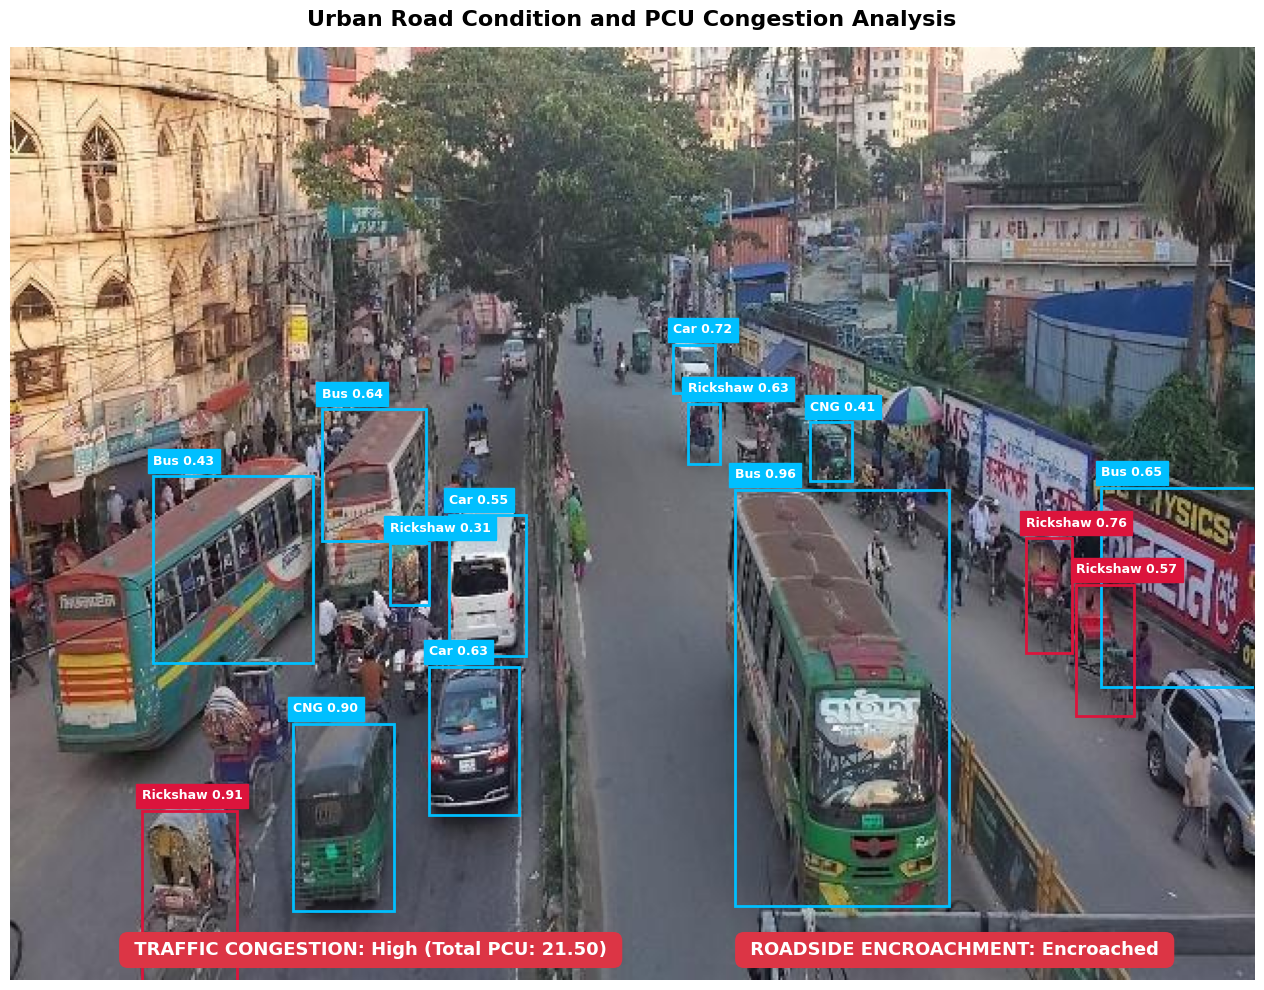

In [5]:
test_images = sorted(glob.glob(f"{INPUT_DATASET_PATH}/test/images/*.*"))

if test_images:
    sample_path = random.choice(test_images)
    print(f"Testing image: {os.path.basename(sample_path)}")
    analyze_road_pcu(sample_path, bench, device, conf_threshold=0.30)
else:
    print("No test images found in the dataset directory.")